In [1]:
import json
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box

#### 1. Add and Inspect Data

In [2]:
borneo = gpd.read_file("Borneo.shp")

with open("fire_archive_SV-C2_834549.json", "r") as f:
    archive_data = json.load(f)
with open("fire_nrt_SV-C2_834549.json", "r") as f:
    nrt_data = json.load(f)

df_archive = pd.DataFrame(archive_data)
df_nrt = pd.DataFrame(nrt_data)

print("Archive records:", len(df_archive))
print("NRT records:", len(df_nrt))

Archive records: 20461
NRT records: 304627


In [3]:
for name, df in [("Archive", df_archive), ("NRT", df_nrt)]:
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    print("Start date:", df["acq_date"].min())
    print("End date:", df["acq_date"].max())
    print("Unique dates:", df["acq_date"].nunique())


Archive
Columns: ['latitude', 'longitude', 'acq_date', 'acq_time', 'instrument', 'satellite', 'bright_t31', 'brightness', 'scan', 'daynight', 'track', 'frp', 'version', 'confidence', 'type']
Start date: 2026-01-01
End date: 2026-07-31
Unique dates: 197

NRT
Columns: ['latitude', 'longitude', 'acq_date', 'acq_time', 'scan', 'bright_t31', 'brightness', 'satellite', 'instrument', 'confidence', 'version', 'frp', 'daynight', 'track']
Start date: 2026-08-01
End date: 2026-10-30
Unique dates: 90


#### 2. Combine archive + NRT into one GeoDataFrame

In [4]:
df_archive["source"] = "Archive"
df_nrt["source"] = "NRT"

df_combined = pd.concat([df_archive, df_nrt], ignore_index=True)

# Parse dates ONCE here (instead of inside the monthly filter function)
df_combined["datetime"] = pd.to_datetime(df_combined["acq_date"])

gdf_combined = gpd.GeoDataFrame(
    df_combined,
    geometry=gpd.points_from_xy(df_combined.longitude, df_combined.latitude),
    crs="EPSG:4326",
)
print("Total detections:", len(gdf_combined))
gdf_combined.head(3)

Total detections: 325088


,latitude,longitude,acq_date,acq_time,instrument,satellite,bright_t31,brightness,scan,daynight,track,frp,version,confidence,type,source,datetime,geometry
0,5.79790,118.04066,2026-01-01,0516,SNPP,SNPP,293.06,326.99,0.55,D,0.43,3.76,2,n,0,Archive,2026-01-01,POINT (118.04066 5.7979)
1,-1.89451,112.10028,2026-01-02,0635,SNPP,SNPP,282.47,332.62,0.33,D,0.55,2.30,2,n,0,Archive,2026-01-02,POINT (112.10028 -1.89451)
2,0.68889,117.54967,2026-01-02,1736,SNPP,SNPP,288.54,309.73,0.39,N,0.36,0.92,2,n,2,Archive,2026-01-02,POINT (117.54967 0.68889)


In [5]:
diff = gdf_combined['confidence'].unique()
print(diff)

<StringArray>
['n', 'l', 'h']
Length: 3, dtype: str


In [26]:
filtered = gdf_combined[gdf_combined['confidence'].isin(["h"])]

#### 3. Projection Check

In [8]:
print("Borneo CRS:", borneo.crs)
print("Fires CRS :", filtered.crs)

Borneo CRS: EPSG:4326
Fires CRS : EPSG:4326


In [27]:
# Clip fire points to Borneo (both layers are in UTM)
fires_bor = gpd.sjoin(filtered, borneo, how="inner", predicate="within")
fires_bor = fires_bor.drop(columns="index_right")   # avoid 'index_right' clash in later joins

print("Detections before clip:", len(filtered))
print("Detections inside Borneo:", len(fires_bor))

Detections before clip: 10989
Detections inside Borneo: 10800


In [17]:
## Assigning Month of Detection for each row

In [28]:
fires_bor["month"] = fires_bor["acq_date"].astype(str).str[5:7].astype(int)

In [29]:
def get_season(m):
    if m in [1, 2, 3]:
        return "Wet Season / Tail End"
    elif m in [4, 5, 6, 7]:
        return "Dry Season"
    elif m in [8, 9, 10]:
        return "Peak of Dry Season"
    else:  # 11, 12
        return "Wet Season"

fires_bor["season"] = fires_bor["month"].apply(get_season)

In [22]:
print(fires_bor["month"].value_counts().sort_index())

month
1       1924
2        756
3       2667
4       1103
5        941
6       1457
7       6908
8      87829
9     110705
10     91915
Name: count, dtype: int64


## Viz

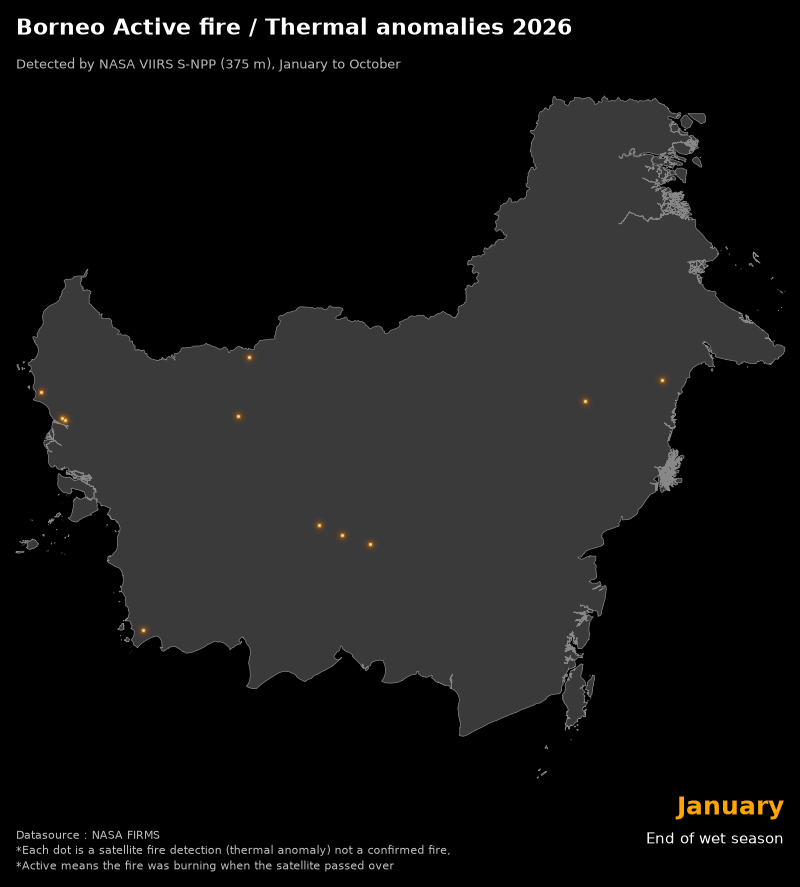

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

MONTH_NAMES = {1: "January", 2: "February", 3: "March", 4: "April",
               5: "May", 6: "June", 7: "July", 8: "August",
               9: "September", 10: "October"}

# 3. Colors
GLOW_ORANGE = "#FF6A00"   # outer glow
CORE_ORANGE = "#FFA500"   # mid layer
HOT_CORE    = "#FFE08A"   # bright center

# 4. Layout: figure shaped like the map, so there are no extra black margins
months = sorted(fires_bor["month"].unique())
minx, miny, maxx, maxy = borneo.total_bounds

PAD_BOTTOM = 0.16   # room for month / season / detections labels
PAD_TOP    = 0.14   # room for the title
PAD_SIDE   = 0.02   # small margin left and right

w = maxx - minx
h = maxy - miny
xlim = (minx - w * PAD_SIDE, maxx + w * PAD_SIDE)
ylim = (miny - h * PAD_BOTTOM, maxy + h * PAD_TOP)

fig_w = 8
fig_h = fig_w * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0])
fig, ax = plt.subplots(figsize=(fig_w, fig_h), facecolor="black")
fig.subplots_adjust(left=0, right=1, top=1, bottom=0)

# 5. Update function
def update(i):
    ax.clear()
    ax.set_facecolor("black")

    m = months[i]
    sub = fires_bor[fires_bor["month"] == m]
    x, y = sub.geometry.x, sub.geometry.y

    # Borneo polygon
    borneo.plot(ax=ax, color="#3a3a3a", edgecolor="#888888", linewidth=0.5)

    # Glow layers: big and faint -> small and bright
    ax.scatter(x, y, s=120, c=GLOW_ORANGE, alpha=0.06, linewidths=0)
    ax.scatter(x, y, s=50,  c=GLOW_ORANGE, alpha=0.12, linewidths=0)
    ax.scatter(x, y, s=18,  c=CORE_ORANGE, alpha=0.35, linewidths=0)
    ax.scatter(x, y, s=5,   c=HOT_CORE,    alpha=0.9,  linewidths=0)

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_aspect("equal")
    ax.axis("off")

    # Title (top left)
    ax.text(0.02, 0.98, "Borneo Active fire / Thermal anomalies 2026",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=16, fontweight="bold", color="white")
    ax.text(0.02, 0.935, "Detected by NASA VIIRS S-NPP (375 m), January to October",
            transform=ax.transAxes, ha="left", va="top",
            fontsize=9, color="#BBBBBB")

    # Month, season, detections (bottom right)
    season = sub["season"].iloc[0] if len(sub) else ""

    ax.text(0.98, 0.075, MONTH_NAMES[m],
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=18, fontweight="bold", color=CORE_ORANGE)
    ax.text(0.98, 0.045, season,
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=11, color="white")


    # Disclaimer (bottom left)
    disclaimer = (
        "Datasource : NASA FIRMS\n"
        "\n"
        "*Each dot is a satellite fire detection (thermal anomaly) not a confirmed fire,\n"
        "*Active means the fire was burning when the satellite passed over"
        
    )

    ax.text(0.02, 0.015, disclaimer,
            transform=ax.transAxes, ha="left", va="bottom",
            fontsize=8, color="#C4C1C1", linespacing=1.4)

# 6. Build, save, show
anim = FuncAnimation(fig, update, frames=len(months), interval=1000)
anim.save("borneo_fires.gif", writer=PillowWriter(fps=1.5), dpi=100,
          savefig_kwargs={"facecolor": "black"})
plt.close(fig)
Image(filename="borneo_fires.gif")

In [62]:
print(fires_bor["month"].value_counts().sort_index())
print(fires_bor["season"].value_counts())

month
1       11
2       17
3       73
4       28
5       10
6       25
7      151
8     3900
9     3866
10    2719
Name: count, dtype: int64
season
Peak dry season      10485
Dry season             214
End of wet season      101
Name: count, dtype: int64



    ax.text(0.98, 0.015, f"{len(sub):,} detections",
            transform=ax.transAxes, ha="right", va="bottom",
            fontsize=11, color="white")